# Import models 

In [1]:
import os
import subprocess
import pandas as pd
import numpy as np
import optuna
from optuna.samplers import NSGAIIISampler
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import AutoMinorLocator
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
import re

C:\Users\hp\anaconda3\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Simulator running script

In [2]:
# =========================
# PATHS
# =========================
ECLRUN_EXE = r"C:\ecl\macros\eclrun.exe"
BASE_DIR = r"C:\Users\hp\Desktop\Eclipsetimesteps"

DATA_FILE_NAME = "Egg_Model_ECL.DATA"
RSM_FILE_NAME = "Egg_Model_ECL.RSM"
RSM_PATH = os.path.join(BASE_DIR, "EGG_MODEL_ECL.RSM")

N_BLOCKS = 5
BLOCK_END_DAYS = 720  # end of each block (24*30)
TARGET_TIMES = [BLOCK_END_DAYS * i for i in range(1, N_BLOCKS + 1)]
FINAL_TIME = TARGET_TIMES[-1]

In [3]:
# =========================
# RUN ECLIPSE
# =========================
def run_eclipse():
    print("▶ Running Eclipse ...")
    cmd = [ECLRUN_EXE, "eclipse", DATA_FILE_NAME]
    subprocess.run(cmd, cwd=BASE_DIR, check=True)
    print("✔ Eclipse finished")

# =========================
# EXTRACT FOPT & FWPT PER BLOCK
# =========================
def extract_FOPT_FWPT_from_RSM(rsm_path):

    with open(rsm_path, "r") as f:
        lines = f.readlines()

    inside_summary = False
    fopt_idx = fwpt_idx = None

    for line in lines:

        if "SUMMARY OF RUN" in line:
            inside_summary = True
            fopt_idx = fwpt_idx = None
            continue

        if not inside_summary:
            continue

        tokens = line.split()
        if not tokens:
            continue

        # Detect column headers
        if fopt_idx is None and "FOPT" in tokens and "FWPT" in tokens:
            fopt_idx = tokens.index("FOPT")
            fwpt_idx = tokens.index("FWPT")
            continue

        if fopt_idx is None:
            continue

        # ✅ Only data rows have numeric TIME
        if not tokens[0][0].isdigit():
            continue
        if float(tokens[0]) == 3600.0:
            return float(tokens[fopt_idx]), float(tokens[fwpt_idx])

In [4]:
def modify_data_per_control_block(blocks_params):

    data_path = os.path.join(BASE_DIR, DATA_FILE_NAME)

    with open(data_path, "r") as f:
        lines = f.readlines()

    block_pattern = re.compile(r"--\s*Block\s+(\d+)", re.IGNORECASE)

    current_block = None
    new_lines = []

    for line in lines:

        # Detect block number
        m = block_pattern.search(line)
        if m:
            current_block = int(m.group(1))
            new_lines.append(line)
            continue

        # Skip if block not in params
        if current_block is None or current_block > len(blocks_params):
            new_lines.append(line)
            continue

        params = blocks_params[current_block - 1]
        stripped = line.strip()

        # -------------------------
        # PRODUCER BHP
        # -------------------------
        prod_match = re.match(r"'PROD(\d+)'", stripped)
        if prod_match and "'BHP'" in stripped:

            prod_num = prod_match.group(1)
            key = f"BHP{prod_num}"

            if key in params:
                bhp_value = int(params[key])

                # Replace last numeric value in line (robust)
                line = re.sub(r"(5\*\s*)(\d+)", rf"\g<1>{bhp_value}", line)

        # -------------------------
        # INJECTOR RATE
        # -------------------------
        inj_match = re.match(r"'INJECT(\d+)'", stripped)
        if inj_match and "'RATE'" in stripped:

            inj_num = inj_match.group(1)
            key = f"inj_rate{inj_num}"

            if key in params:
                rate_value = int(params[key])

                # Replace RATE value robustly
                line = re.sub(r"('RATE'\s+)(\d+)", rf"\g<1>{rate_value}", line)

        new_lines.append(line)

    with open(data_path, "w") as f:
        f.writelines(new_lines)

# Define objective function with contraint & Optimization running :

In [5]:
# ---------------------------------------------------------------------------
# BHP settings
# ---------------------------------------------------------------------------
BHP_LOW = 150                    
BHP_HIGH = 390                   
INITIAL_RESERVOIR_PRESSURE = 400  

MAX_BHP_GAP = 20                  
MIN_TEMPORAL_DROP = 1             

N_PRODUCERS = 4
N_INJECTORS = 8

CENTER_MODE = "direct"

HALF_GAP = MAX_BHP_GAP // 2                                 
CENTER_LOW = BHP_LOW + HALF_GAP                            
CENTER_HIGH = BHP_HIGH - HALF_GAP                           
DROP_PER_BLOCK = 2 * HALF_GAP + MIN_TEMPORAL_DROP 

# ---------------------------------------------------------------------------
# Constraint 3: every producer keeps producing (WLPR from the RSM file)
# ---------------------------------------------------------------------------
PRODUCER_NAMES = ["PROD1", "PROD2", "PROD3", "PROD4"]  
MIN_LIQ_RATE = 0.1          
START_TOLERANCE_REPORTS = 6  

In [6]:
# ---------------------------------------------------------------------------
# 1. Read any vector from the RSM (several tab-separated blocks, well names row)
# ---------------------------------------------------------------------------
def _multiplier(cell):
    cell = cell.strip()
    return 10.0 ** int(cell[5:]) if cell.startswith("*10**") else 1.0


def read_rsm(rsm_path):
    """-> {(VECTOR, WELL or ''): np.array}, with key ('TIME', '') for the times."""
    with open(rsm_path, "r", errors="ignore") as f:
        lines = [ln.rstrip("\r\n") for ln in f]
    if not lines:
        raise ValueError(f"{rsm_path} is empty")

    data = {}
    i = 0
    while i < len(lines):
        if "SUMMARY OF RUN" not in lines[i]:
            i += 1
            continue
        names = [c.strip() for c in lines[i + 1].split("\t")]
        units = [c.strip() for c in lines[i + 2].split("\t")]
        wells = [c.strip() for c in lines[i + 3].split("\t")]
        mults = [_multiplier(c) for c in lines[i + 4].split("\t")]
        n = len(names)
        wells += [""] * (n - len(wells))
        mults += [1.0] * (n - len(mults))
        cols = [(j, names[j], wells[j]) for j in range(n) if names[j]]
        t_col = names.index("TIME")
        i += 5

        block = {(v, w): [] for _, v, w in cols}
        times = []
        while i < len(lines) and "SUMMARY OF RUN" not in lines[i]:
            cells = lines[i].split("\t")
            i += 1
            try:
                t = float(cells[t_col])
            except (ValueError, IndexError):
                continue
            times.append(t)
            for j, v, w in cols:
                try:
                    block[(v, w)].append(float(cells[j]) * mults[j])
                except (ValueError, IndexError):
                    block[(v, w)].append(np.nan)

        if ("TIME", "") not in data:
            data[("TIME", "")] = np.array(times)
        elif len(times) != len(data[("TIME", "")]):
            raise ValueError("RSM blocks have different numbers of rows")
        for key, vals in block.items():
            if key != ("TIME", ""):
                data[key] = np.array(vals)
    return data


def read_WLPR(rsm_path, wells=PRODUCER_NAMES):
    """-> times, {well: WLPR array (sm3/day)}."""
    d = read_rsm(rsm_path)
    missing = [w for w in wells if ("WLPR", w) not in d]
    if missing:
        raise KeyError(f"WLPR missing in the RSM for {missing} - add 'WLPR' / to SUMMARY")
    return d[("TIME", "")], {w: d[("WLPR", w)] for w in wells}

In [7]:
# ---------------------------------------------------------------------------
# 2. Feasibility
# ---------------------------------------------------------------------------
def check_producers_active(rsm_path, wells=PRODUCER_NAMES, min_rate=MIN_LIQ_RATE,
                           start_tolerance=START_TOLERANCE_REPORTS):
   
    t, wlpr = read_WLPR(rsm_path, wells)
    idx = np.where(t > 0)[0][start_tolerance:]          # report steps that are checked
    if len(idx) == 0:
        raise ValueError("No report step left after the start tolerance")
    constraints, report = [], {}
    for w in wells:
        q = wlpr[w][idx]
        dead = t[idx][q <= min_rate]
        start_zeros = int(np.sum(wlpr[w][np.where(t > 0)[0][:start_tolerance]] <= min_rate))
        constraints.append(float(min_rate - np.nanmin(q)))
        report[w] = {"min_WLPR": float(np.nanmin(q)),
                     "first_shut_day": float(dead[0]) if len(dead) else None,
                     "n_shut_reports": int(len(dead)),
                     "start_zeros_accepted": start_zeros}
    feasible = all(c <= 0 for c in constraints)
    return feasible, constraints, report


def store_feasibility(trial, rsm_path):
   
    feasible, constraints, report = check_producers_active(rsm_path)
    trial.set_user_attr("constraints", constraints)
    trial.set_user_attr("feasible", feasible)
    for w, r in report.items():
        trial.set_user_attr(f"min_WLPR_{w}", round(r["min_WLPR"], 3))
        trial.set_user_attr(f"shut_day_{w}", r["first_shut_day"])
    return feasible


def constraints_func(trial):
    
    return trial.user_attrs.get("constraints", [1e6])


def feasible_pareto(study):
    
    return [t for t in study.best_trials if t.user_attrs.get("feasible", False)]




def check_feasibility(n_blocks):
    
    first_high = min(CENTER_HIGH, INITIAL_RESERVOIR_PRESSURE - MIN_TEMPORAL_DROP - HALF_GAP)
    needed = CENTER_LOW + (n_blocks - 1) * DROP_PER_BLOCK
    if needed > first_high:
        max_blocks = (first_high - CENTER_LOW) // DROP_PER_BLOCK + 1
        raise ValueError(f"{n_blocks} blocks are not feasible; maximum is {max_blocks} "
                         f"with MAX_BHP_GAP={MAX_BHP_GAP}, BHP range {BHP_LOW}-{BHP_HIGH}.")

In [8]:
def objective(trial):

    blocks_params = []
    previous_min_BHP = INITIAL_RESERVOIR_PRESSURE

    for b in range(1, N_BLOCKS + 1):

        # -----------------------------------------------------------
        # 1. Feasible range of the centred BHP of this block
        # -----------------------------------------------------------
        # constraint 2: every BHP of block b below the minimum BHP of block b-1
        max_allowed_BHP = previous_min_BHP - MIN_TEMPORAL_DROP
        center_high = min(CENTER_HIGH, max_allowed_BHP - HALF_GAP)
        # leave room so that the remaining blocks can still go lower
        center_low = CENTER_LOW + (N_BLOCKS - b) * DROP_PER_BLOCK

        if center_high < center_low:                 # impossible after check_feasibility()
            raise optuna.TrialPruned(f"No feasible BHP centre in block {b}")

        # -----------------------------------------------------------
        # 2. Centred BHP (bar)
        # -----------------------------------------------------------
        if CENTER_MODE == "direct":
            BHP_center = trial.suggest_int(f"BHP_center_b{b}", center_low, center_high)
        else:
            frac = trial.suggest_float(f"BHP_center_frac_b{b}", 0.0, 1.0)
            BHP_center = center_low + int(round(frac * (center_high - center_low)))

        # -----------------------------------------------------------
        # 3. Producer BHPs = centre + offset, offset in [-10, +10]
        #    -> constraint 1: max - min <= 20 bar
        # -----------------------------------------------------------
        producer_BHPs = [
            BHP_center + trial.suggest_int(f"BHP{p}_offset_b{b}", -HALF_GAP, HALF_GAP)
            for p in range(1, N_PRODUCERS + 1)
        ]

        gap = max(producer_BHPs) - min(producer_BHPs)
        if gap > MAX_BHP_GAP:
            raise RuntimeError(f"Constraint 1 violated in block {b}: gap = {gap}")
        if max(producer_BHPs) >= previous_min_BHP:
            raise RuntimeError(f"Constraint 2 violated in block {b}: "
                               f"{max(producer_BHPs)} >= {previous_min_BHP}")
        if min(producer_BHPs) < BHP_LOW or max(producer_BHPs) > BHP_HIGH:
            raise RuntimeError(f"BHP outside {BHP_LOW}-{BHP_HIGH} in block {b}")

        # -----------------------------------------------------------
        # 4. Injection rates
        # -----------------------------------------------------------
        params = {f"BHP{p}": producer_BHPs[p - 1] for p in range(1, N_PRODUCERS + 1)}
        for i in range(1, N_INJECTORS + 1):
            params[f"inj_rate{i}"] = trial.suggest_int(f"inj_rate{i}_b{b}", 50, 400)
        blocks_params.append(params)

        # store the centred BHP and the real BHPs of the block with the trial
        trial.set_user_attr(f"BHP_center_b{b}", BHP_center)
        for p, v in enumerate(producer_BHPs, 1):
            trial.set_user_attr(f"BHP{p}_b{b}", v)
        trial.set_user_attr(f"gap_b{b}", gap)
        trial.set_user_attr(f"drop_b{b}", previous_min_BHP - max(producer_BHPs))

        previous_min_BHP = min(producer_BHPs)

    # ---------------------------------------------------------------
    # 5. Modify schedule, run Eclipse, read FOPT / FWPT
    # ---------------------------------------------------------------
    modify_data_per_control_block(blocks_params)

    if os.path.exists(RSM_PATH):                 # never read the RSM of a previous run
        os.remove(RSM_PATH)
    try:
        run_eclipse()
        fopt, fwpt = extract_FOPT_FWPT_from_RSM(RSM_PATH)
    except (subprocess.CalledProcessError, subprocess.TimeoutExpired,
            FileNotFoundError, ValueError, KeyError, IndexError) as e:
        trial.set_user_attr("status", f"failed: {e}")
        raise optuna.TrialPruned("Eclipse run failed")

    # constraint 3: no producer shut in (zeros accepted in the first report steps)
    try:
        feasible = store_feasibility(trial, RSM_PATH)
    except (FileNotFoundError, ValueError, KeyError) as e:
        trial.set_user_attr("status", f"WLPR not readable: {e}")
        raise optuna.TrialPruned("WLPR could not be read")

    trial.set_user_attr("FOPT", fopt)
    trial.set_user_attr("FWPT", fwpt)
    trial.set_user_attr("status", "ok" if feasible else "infeasible: producer shut in")
    return fopt, fwpt


def print_solution(t):
    """Print a trial with the centred BHP and the real producer BHPs of each block."""
    print(f"Trial Number : {t.number}")
    print(f"FOPT         : {t.values[0]:.1f}")
    print(f"FWPT         : {t.values[1]:.1f}")
    print(f"Feasible     : {t.user_attrs.get('feasible')}\n")
    print(f"{'block':>5} {'center':>7} " + " ".join(f"{'BHP' + str(p):>6}" for p in range(1, N_PRODUCERS + 1))
          + f" {'gap':>5} {'drop':>5}")
    for b in range(1, N_BLOCKS + 1):
        ua = t.user_attrs
        print(f"{b:5d} {ua[f'BHP_center_b{b}']:7d} "
              + " ".join(f"{ua[f'BHP{p}_b{b}']:6d}" for p in range(1, N_PRODUCERS + 1))
              + f" {ua[f'gap_b{b}']:5d} {ua[f'drop_b{b}']:5d}")
    print("\nInjection rates:")
    for b in range(1, N_BLOCKS + 1):
        print(f"  block {b}: " + ", ".join(str(t.params[f'inj_rate{i}_b{b}'])
                                           for i in range(1, N_INJECTORS + 1)))
    print("\nMinimum WLPR after start-up (sm3/d):")
    for w in PRODUCER_NAMES:
        print(f"  {w}: {t.user_attrs.get(f'min_WLPR_{w}')}  "
              f"(first shut-in day: {t.user_attrs.get(f'shut_day_{w}')})")

In [9]:
# ---------------------------------------------------------------------------
# Study
# ---------------------------------------------------------------------------
if __name__ == "__main__":
    check_feasibility(N_BLOCKS)

    study = optuna.create_study(
        directions=["maximize", "minimize"],          # FOPT max, FWPT min
        sampler=optuna.samplers.TPESampler(
            seed=42,
            n_startup_trials=20,
            constraints_func=constraints_func,        # producers must keep producing
        ),
    )
    study.optimize(objective, n_trials=100)

    solutions = feasible_pareto(study)                # infeasible trials are never used
    print(f"\n{len(solutions)} feasible Pareto solutions "
          f"({len(study.best_trials)} on the Pareto front in total)\n")
    for t in solutions:
        print("========== CONSTRAINED OPTIMAL SOLUTION ==========")
        print_solution(t)
        print()

C:\Users\hp\anaconda3\Lib\site-packages\optuna\samplers\_tpe\sampler.py:345: ExperimentalWarning: The ``constraints_func`` option is an experimental feature. The interface can change in the future.
  warnings.warn(
[I 2026-11-14 23:25:20,104] A new study created in memory with name: no-name-c5b637cc-6dea-44d1-9ae4-fd7531f62abc


▶ Running Eclipse ...


[I 2026-11-14 23:27:34,442] Trial 0 finished with values: [543312.4, 5572374.0] and parameters: {'BHP_center_b1': 295, 'BHP1_offset_b1': 9, 'BHP2_offset_b1': 5, 'BHP3_offset_b1': 2, 'BHP4_offset_b1': -7, 'inj_rate1_b1': 104, 'inj_rate2_b1': 70, 'inj_rate3_b1': 354, 'inj_rate4_b1': 260, 'inj_rate5_b1': 298, 'inj_rate6_b1': 57, 'inj_rate7_b1': 390, 'inj_rate8_b1': 342, 'BHP_center_b2': 234, 'BHP1_offset_b2': -7, 'BHP2_offset_b2': -7, 'BHP3_offset_b2': -4, 'BHP4_offset_b2': 1, 'inj_rate1_b2': 201, 'inj_rate2_b2': 152, 'inj_rate3_b2': 264, 'inj_rate4_b2': 98, 'inj_rate5_b2': 152, 'inj_rate6_b2': 178, 'inj_rate7_b2': 210, 'inj_rate8_b2': 325, 'BHP_center_b3': 204, 'BHP1_offset_b3': 0, 'BHP2_offset_b3': 2, 'BHP3_offset_b3': -10, 'BHP4_offset_b3': 2, 'inj_rate1_b3': 109, 'inj_rate2_b3': 72, 'inj_rate3_b3': 383, 'inj_rate4_b3': 388, 'inj_rate5_b3': 333, 'inj_rate6_b3': 156, 'inj_rate7_b3': 84, 'inj_rate8_b3': 290, 'BHP_center_b4': 182, 'BHP1_offset_b4': -8, 'BHP2_offset_b4': 0, 'BHP3_offset_b4

✔ Eclipse finished
▶ Running Eclipse ...


[I 2026-11-14 23:30:08,678] Trial 1 finished with values: [539818.5, 5449790.0] and parameters: {'BHP_center_b1': 318, 'BHP1_offset_b1': -8, 'BHP2_offset_b1': 6, 'BHP3_offset_b1': -9, 'BHP4_offset_b1': 10, 'inj_rate1_b1': 321, 'inj_rate2_b1': 119, 'inj_rate3_b1': 51, 'inj_rate4_b1': 336, 'inj_rate5_b1': 298, 'inj_rate6_b1': 305, 'inj_rate7_b1': 320, 'inj_rate8_b1': 75, 'BHP_center_b2': 250, 'BHP1_offset_b2': -8, 'BHP2_offset_b2': 8, 'BHP3_offset_b2': 3, 'BHP4_offset_b2': -4, 'inj_rate1_b2': 72, 'inj_rate2_b2': 159, 'inj_rate3_b2': 164, 'inj_rate4_b2': 306, 'inj_rate5_b2': 273, 'inj_rate6_b2': 361, 'inj_rate7_b2': 215, 'inj_rate8_b2': 91, 'BHP_center_b3': 223, 'BHP1_offset_b3': 5, 'BHP2_offset_b3': 1, 'BHP3_offset_b3': 6, 'BHP4_offset_b3': 0, 'inj_rate1_b3': 233, 'inj_rate2_b3': 200, 'inj_rate3_b3': 58, 'inj_rate4_b3': 87, 'inj_rate5_b3': 61, 'inj_rate6_b3': 273, 'inj_rate7_b3': 160, 'inj_rate8_b3': 228, 'BHP_center_b4': 210, 'BHP1_offset_b4': -5, 'BHP2_offset_b4': -2, 'BHP3_offset_b4':

✔ Eclipse finished
▶ Running Eclipse ...


... (192 outputs left out)

[I 2026-11-15 02:07:47,000] Trial 98 finished with values: [540771.7, 5803524.0] and parameters: {'BHP_center_b1': 312, 'BHP1_offset_b1': -4, 'BHP2_offset_b1': -1, 'BHP3_offset_b1': 7, 'BHP4_offset_b1': 4, 'inj_rate1_b1': 96, 'inj_rate2_b1': 112, 'inj_rate3_b1': 384, 'inj_rate4_b1': 138, 'inj_rate5_b1': 297, 'inj_rate6_b1': 146, 'inj_rate7_b1': 163, 'inj_rate8_b1': 333, 'BHP_center_b2': 291, 'BHP1_offset_b2': -4, 'BHP2_offset_b2': 0, 'BHP3_offset_b2': 4, 'BHP4_offset_b2': -1, 'inj_rate1_b2': 192, 'inj_rate2_b2': 242, 'inj_rate3_b2': 342, 'inj_rate4_b2': 343, 'inj_rate5_b2': 110, 'inj_rate6_b2': 204, 'inj_rate7_b2': 85, 'inj_rate8_b2': 245, 'BHP_center_b3': 245, 'BHP1_offset_b3': -10, 'BHP2_offset_b3': -5, 'BHP3_offset_b3': 9, 'BHP4_offset_b3': 3, 'inj_rate1_b3': 355, 'inj_rate2_b3': 259, 'inj_rate3_b3': 120, 'inj_rate4_b3': 371, 'inj_rate5_b3': 102, 'inj_rate6_b3': 252, 'inj_rate7_b3': 166, 'inj_rate8_b3': 116, 'BHP_center_b4': 217, 'BHP1_offset_b4': 9, 'BHP2_offset_b4': 4, 'BHP3_offse

✔ Eclipse finished
▶ Running Eclipse ...


[I 2026-11-15 02:09:05,022] Trial 99 finished with values: [542757.8, 5916462.0] and parameters: {'BHP_center_b1': 347, 'BHP1_offset_b1': 0, 'BHP2_offset_b1': 3, 'BHP3_offset_b1': 10, 'BHP4_offset_b1': 3, 'inj_rate1_b1': 335, 'inj_rate2_b1': 76, 'inj_rate3_b1': 326, 'inj_rate4_b1': 217, 'inj_rate5_b1': 120, 'inj_rate6_b1': 196, 'inj_rate7_b1': 128, 'inj_rate8_b1': 381, 'BHP_center_b2': 315, 'BHP1_offset_b2': -3, 'BHP2_offset_b2': -3, 'BHP3_offset_b2': 2, 'BHP4_offset_b2': 1, 'inj_rate1_b2': 258, 'inj_rate2_b2': 172, 'inj_rate3_b2': 130, 'inj_rate4_b2': 271, 'inj_rate5_b2': 376, 'inj_rate6_b2': 131, 'inj_rate7_b2': 189, 'inj_rate8_b2': 350, 'BHP_center_b3': 287, 'BHP1_offset_b3': -3, 'BHP2_offset_b3': 0, 'BHP3_offset_b3': 3, 'BHP4_offset_b3': 8, 'inj_rate1_b3': 98, 'inj_rate2_b3': 194, 'inj_rate3_b3': 302, 'inj_rate4_b3': 309, 'inj_rate5_b3': 310, 'inj_rate6_b3': 353, 'inj_rate7_b3': 216, 'inj_rate8_b3': 235, 'BHP_center_b4': 257, 'BHP1_offset_b4': -1, 'BHP2_offset_b4': 7, 'BHP3_offset_

✔ Eclipse finished

11 feasible Pareto solutions (14 on the Pareto front in total)

========== CONSTRAINED OPTIMAL SOLUTION ==========
Trial Number : 8
FOPT         : 547583.6
FWPT         : 5984132.0
Feasible     : True

block  center   BHP1   BHP2   BHP3   BHP4   gap  drop
    1     264    266    261    274    271    13   126
    2     250    251    256    259    257     8     2
    3     215    207    219    215    221    14    30
    4     193    196    197    187    185    12    10
    5     171    169    174    179    180    11     5

Injection rates:
  block 1: 344, 214, 195, 145, 69, 353, 335, 400
  block 2: 136, 208, 95, 384, 262, 130, 285, 266
  block 3: 232, 349, 243, 246, 357, 191, 97, 60
  block 4: 55, 173, 257, 187, 203, 367, 172, 230
  block 5: 101, 375, 222, 140, 211, 393, 222, 165

Minimum WLPR after start-up (sm3/d):
  PROD1: 258.452  (first shut-in day: None)
  PROD2: 597.085  (first shut-in day: None)
  PROD3: 155.401  (first shut-in day: None)
  PROD4: 152.004  (fi

# The plot of FOPT & FWPT :

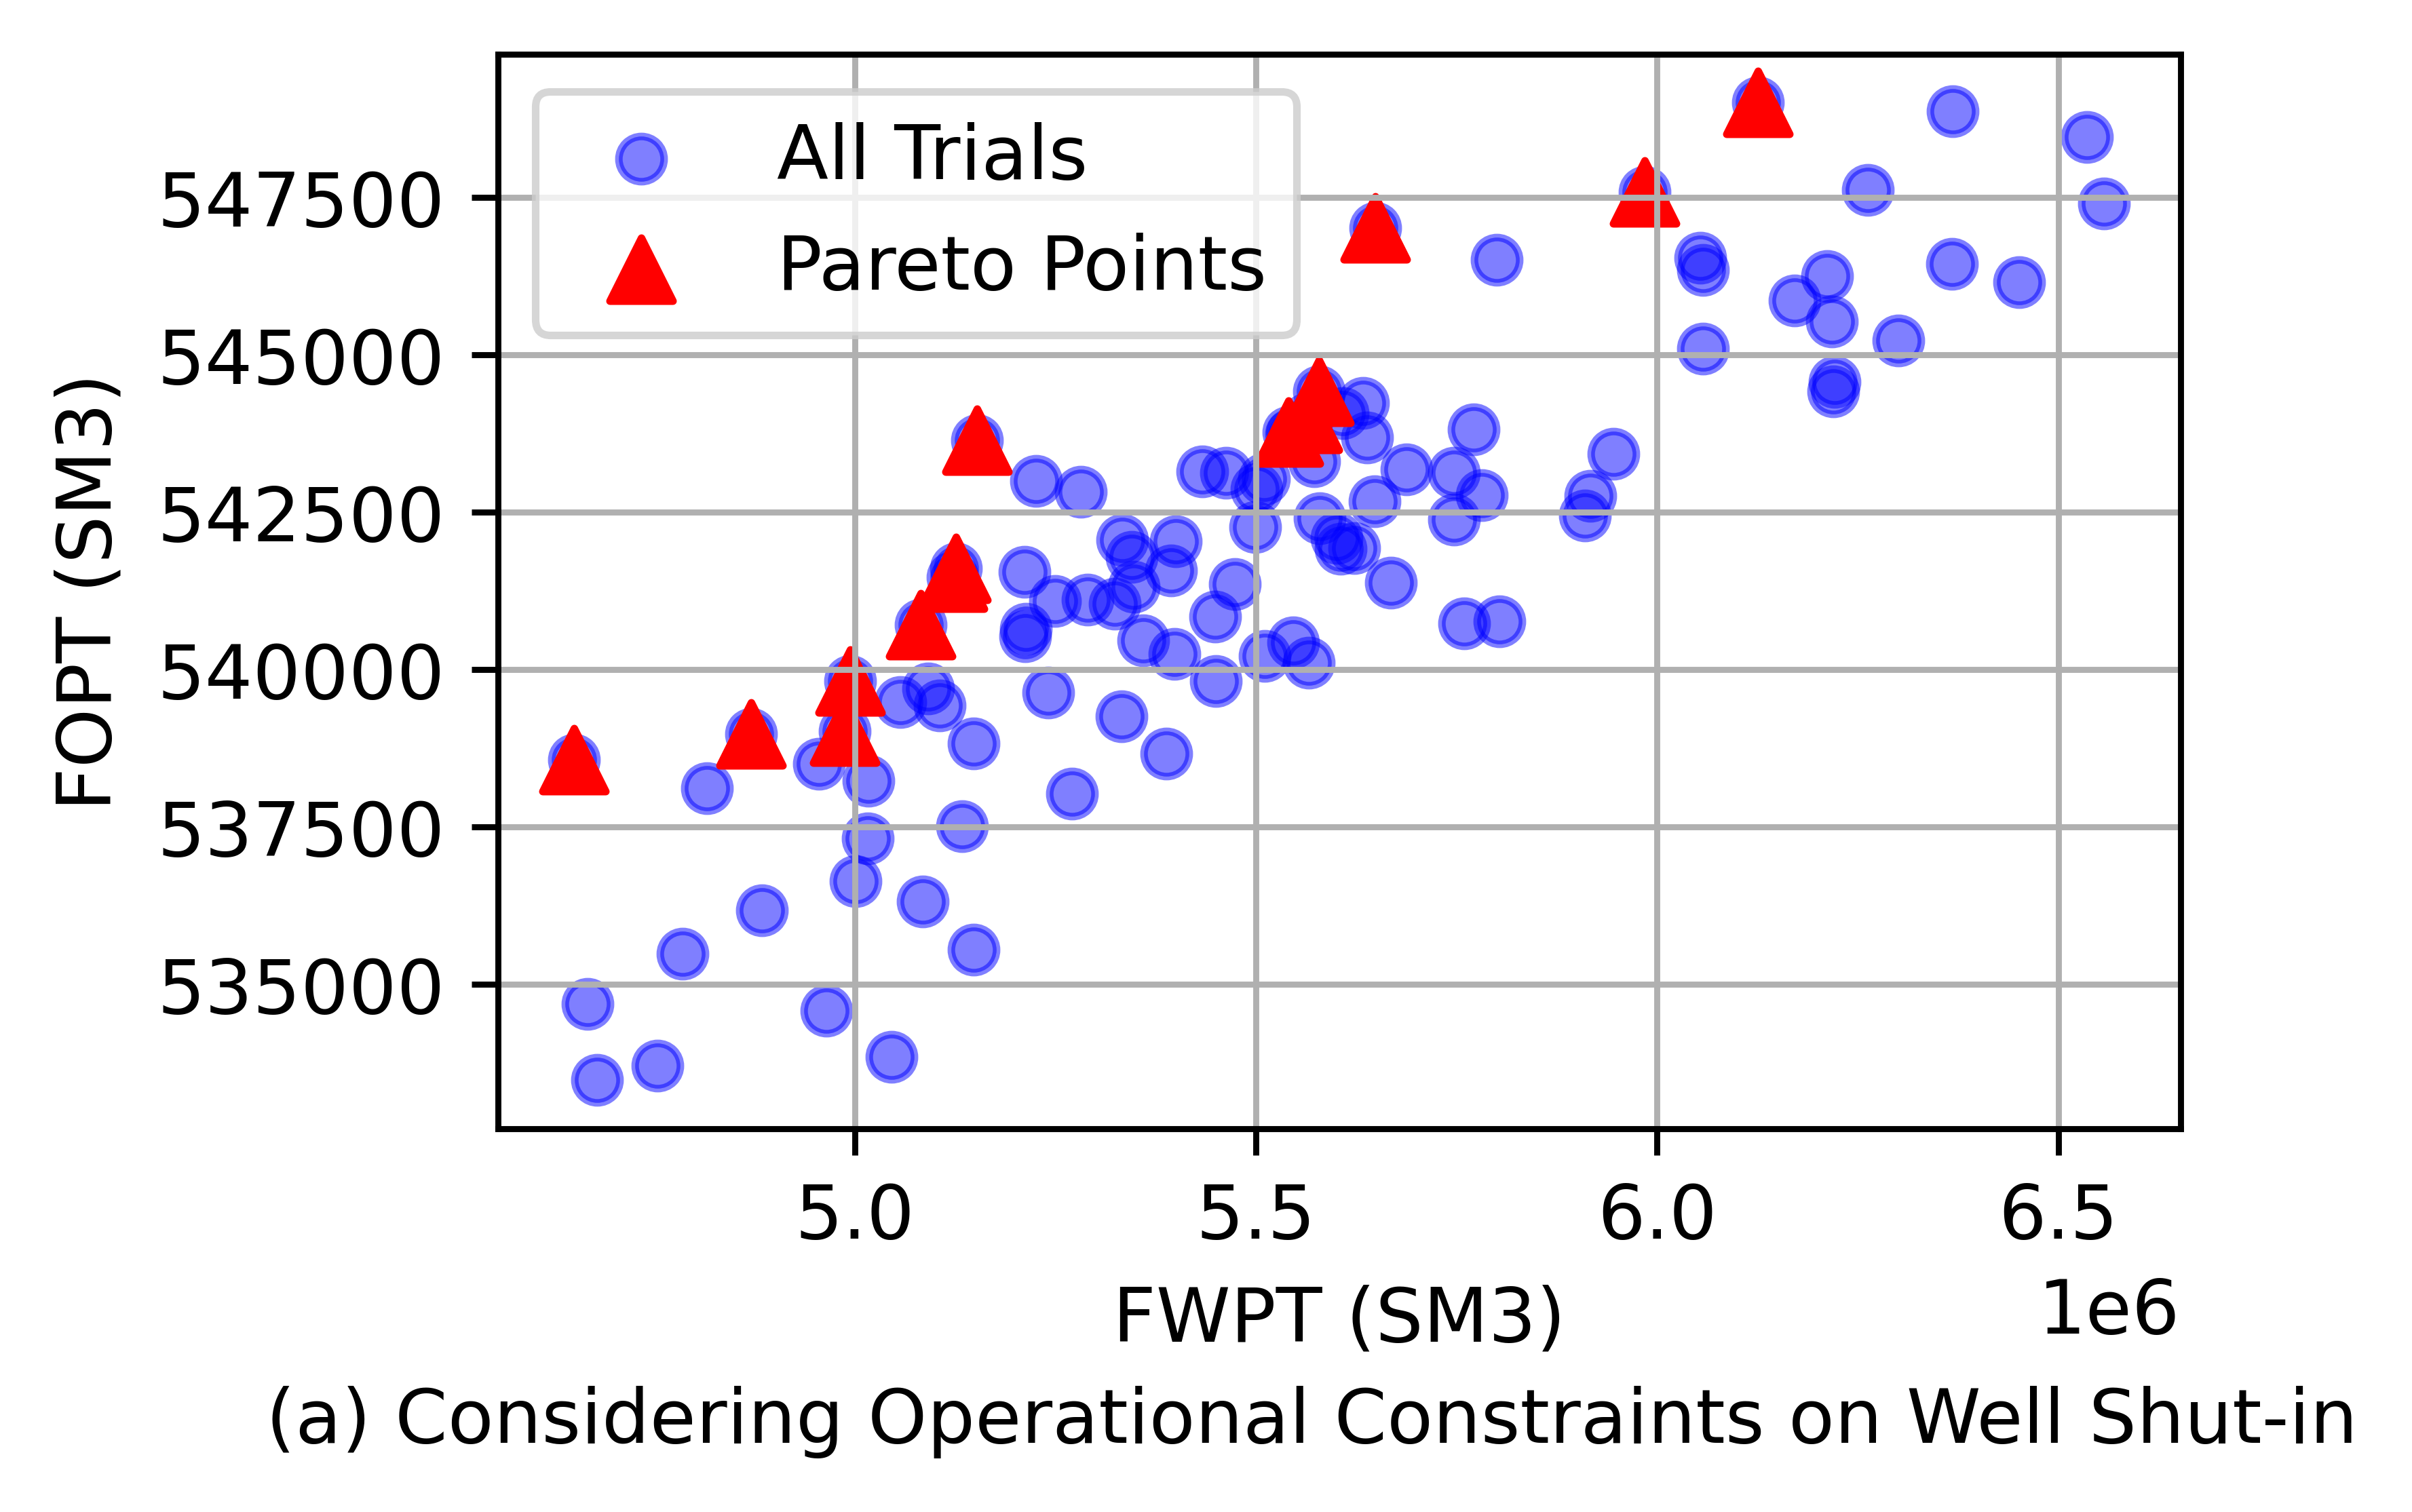

In [10]:
# --- Pareto optimal trials ---
pareto_trials1 = study.best_trials
pareto_fopts = [t.values[0] for t in pareto_trials1]
pareto_fwpts = [t.values[1] for t in pareto_trials1]

# --- Sort Pareto points by FWPT (minimization axis) ---
pareto_points = sorted(zip(pareto_fwpts, pareto_fopts))
pareto_fwpts_sorted, pareto_fopts_sorted = zip(*pareto_points)

# --- All trials ---
fopts = [t.values[0] for t in study.trials if t.values is not None]
fwpts = [t.values[1] for t in study.trials if t.values is not None]

# Create figure
fig, ax = plt.subplots(figsize=(4, 3), dpi=800)

# All solutions
ax.scatter(
    fwpts,
    fopts,
    color='blue',
    alpha=0.5,
    label='All Trials'
)

# Pareto points
ax.scatter(
    pareto_fwpts_sorted,
    pareto_fopts_sorted,
    color='red',
    marker='^',
    s=70,
    label='Pareto Points'
)

# Labels
ax.set_xlabel("FWPT (SM3)")
ax.set_ylabel("FOPT (SM3)")

# Legend and grid
ax.legend()
ax.grid(True)

# Leave space for caption
plt.subplots_adjust(bottom=0.22)

# Add caption below the figure
fig.text(
    0.5,
    0.04,
    "(a) Considering Operational Constraints on Well Shut-in",
    ha="center",
    va="center",
    fontsize=10
)

# Save (optional)
plt.savefig(
    "Optimization_results_second_approach.png",
    dpi=800,
    bbox_inches="tight"
)

plt.show()

In [13]:
# Constraint definition
# ===============================
FWPT_max = 6200000  # constraint on water production

# Extract Pareto values
fopt = np.array([t.values[0] for t in pareto_trials1])
fwpt = np.array([t.values[1] for t in pareto_trials1])

# ===============================
# Apply constraint (FWPT <= limit)
# ===============================
valid_indices = [i for i, fw in enumerate(fwpt) if fw <= FWPT_max]

if valid_indices:

    # Select best FOPT among valid ones
    best_idx = max(valid_indices, key=lambda i: fopt[i])
    best_trial_constraint = pareto_trials1[best_idx]

    # --- Extract values ---
    best_fopt = best_trial_constraint.values[0]
    best_fwpt = best_trial_constraint.values[1]
    params = best_trial_constraint.params

    # --- Separate BHP and Injection rates ---
    bhp_params = {k: v for k, v in params.items() if "BHP" in k}
    inj_params = {k: v for k, v in params.items() if "inj" in k.lower()}

    # --- Print results ---
    print("========== CONSTRAINED OPTIMAL SOLUTION ==========")
    print(f"Trial Number : {best_trial_constraint.number}")
    print(f"FOPT         : {best_fopt}")
    print(f"FWPT         : {best_fwpt}")

    print("\n--- BHP Parameters ---")
    for k, v in bhp_params.items():
        print(f"{k}: {v}")

    print("\n--- Injection Rate Parameters ---")
    for k, v in inj_params.items():
        print(f"{k}: {v}")

else:
    print("No Pareto solution satisfies the FWPT constraint.")

========== CONSTRAINED OPTIMAL SOLUTION ==========
Trial Number : 15
FOPT         : 549004.8
FWPT         : 6125416.0

--- BHP Parameters ---
BHP_center_b1: 248
BHP1_offset_b1: -5
BHP2_offset_b1: 2
BHP3_offset_b1: -9
BHP4_offset_b1: 0
BHP_center_b2: 225
BHP1_offset_b2: -5
BHP2_offset_b2: 7
BHP3_offset_b2: 6
BHP4_offset_b2: 4
BHP_center_b3: 203
BHP1_offset_b3: 1
BHP2_offset_b3: 8
BHP3_offset_b3: 5
BHP4_offset_b3: 6
BHP_center_b4: 181
BHP1_offset_b4: 4
BHP2_offset_b4: 9
BHP3_offset_b4: -7
BHP4_offset_b4: 1
BHP_center_b5: 163
BHP1_offset_b5: 7
BHP2_offset_b5: -4
BHP3_offset_b5: 7
BHP4_offset_b5: -10

--- Injection Rate Parameters ---
inj_rate1_b1: 259
inj_rate2_b1: 167
inj_rate3_b1: 320
inj_rate4_b1: 87
inj_rate5_b1: 76
inj_rate6_b1: 305
inj_rate7_b1: 223
inj_rate8_b1: 291
inj_rate1_b2: 145
inj_rate2_b2: 257
inj_rate3_b2: 176
inj_rate4_b2: 82
inj_rate5_b2: 371
inj_rate6_b2: 98
inj_rate7_b2: 383
inj_rate8_b2: 206
inj_rate1_b3: 281
inj_rate2_b3: 292
inj_rate3_b3: 348
inj_rate4_b3: 137
inj_r

# Pareto front optimal results

In [14]:
print("\nPareto Front Table\n")
print("Trial\tFOPT\tFWPT")

for trial in pareto_trials1:
    print(f"{trial.number}\t{trial.values[0]:.2f}\t{trial.values[1]:.2f}")


Pareto Front Table

Trial	FOPT	FWPT
8	547583.60	5984132.00
15	549004.80	6125416.00
30	538566.30	4650501.00
33	543777.30	5540666.00
38	544419.40	5578955.00
42	547019.90	5648352.00
44	543643.10	5152738.00
59	539817.10	4994528.00
61	541605.50	5126117.00
62	538980.80	4870982.00
63	540712.90	5082376.00
65	541468.40	5122036.00
76	539022.10	4987468.00
93	543988.50	5564130.00
